In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import torch

from energia.dataset import cargar_datos_modelo
from energia.entrenamiento import (fijar_semilla, dispositivo, contar_parametros, entrenar, predecir,
                                   guardar_modelo, guardar_resultados)
from energia.metricas import evaluar, error_por_hora, naive_estacional, tabla
from energia.modelos import rnn
from energia.visualizacion import estilo, guardar_figura, curvas_aprendizaje, pronostico_vs_real

estilo()
NOMBRE = "rnn"
fijar_semilla()
print("torch", torch.__version__, "| dispositivo:", dispositivo())

ModuleNotFoundError: No module named 'energia'

In [2]:
datos = cargar_datos_modelo()
datos.resumen()

,muestras,pasado,futuro,y,primer_t0,ultimo_t0
split,,,,,,
train,30265,"(30265, 168, 16)","(30265, 24, 9)","(30265, 24, 2)",2022-01-16,2025-06-30
val,184,"(184, 168, 16)","(184, 24, 9)","(184, 24, 2)",2025-07-01,2025-12-31
test,243,"(243, 168, 16)","(243, 24, 9)","(243, 24, 2)",2026-01-01,2026-08-31


In [3]:
HP_MODELO = {"oculto": 64, "capas": 2, "dropout": 0.1, "cabeza": 128}
HP_ENTRENAMIENTO = {"optimizador": "adam", "lr": 1e-3, "epocas": 50, "batch": 256, "paciencia": 8, "clip": 1.0}

modelo = rnn.construir(datos, **HP_MODELO)
print(modelo)
print("parámetros entrenables:", contar_parametros(modelo))

RNNPronostico(
  (rnn): RNN(16, 64, num_layers=2, batch_first=True, dropout=0.1)
  (cabeza): Sequential(
    (0): Linear(in_features=280, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.1, inplace=False)
    (3): Linear(in_features=128, out_features=48, bias=True)
  )
)
parámetros entrenables: 55728


In [4]:
historial = entrenar(modelo, datos, **HP_ENTRENAMIENTO)

época   1 | train 0.2655 | val 0.3039 | 290.2 s *
época   2 | train 0.1123 | val 0.2525 | 215.7 s *
época   3 | train 0.1025 | val 0.2198 | 326.7 s *
época   4 | train 0.0968 | val 0.2166 | 153.1 s *
época   5 | train 0.0920 | val 0.2128 | 161.4 s *
época   6 | train 0.0882 | val 0.1996 | 396.8 s *
época   7 | train 0.0854 | val 0.2089 | 265.9 s
época   8 | train 0.0832 | val 0.2068 | 115.8 s
época   9 | train 0.0812 | val 0.2218 |  79.2 s
época  10 | train 0.0790 | val 0.2187 | 143.2 s
época  11 | train 0.0775 | val 0.2039 | 145.0 s
época  12 | train 0.0765 | val 0.1971 | 122.3 s *
época  13 | train 0.0755 | val 0.1940 | 109.4 s *
época  14 | train 0.0742 | val 0.2332 | 127.9 s
época  15 | train 0.0730 | val 0.2056 |  99.2 s
época  16 | train 0.0723 | val 0.2152 | 152.5 s
época  17 | train 0.0712 | val 0.2413 | 123.5 s
época  18 | train 0.0710 | val 0.2272 | 111.7 s
época  19 | train 0.0707 | val 0.2285 | 128.3 s
época  20 | train 0.0694 | val 0.2158 | 129.6 s
época  21 | train 0.0684

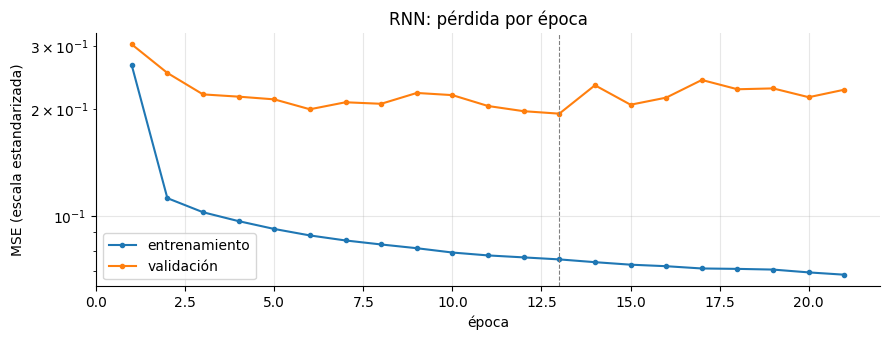

,train,val,segundos
epoca,,,
13,0.075529,0.194008,109.373178


In [5]:
fig = curvas_aprendizaje(historial, "RNN: pérdida por época")
guardar_figura(fig, "f2_01_rnn_curvas")
plt.show()
historial.loc[[historial["val"].idxmin()]]

In [6]:
resultados = {}
predicciones = {}
for split in ["val", "test"]:
    y = datos.y_original(split)
    predicciones[split] = predecir(modelo, datos, split)
    resultados[("rnn", split)] = evaluar(y, predicciones[split])
    resultados[("naive_m24", split)] = evaluar(y, naive_estacional(datos, split, m=24))
    resultados[("naive_m168", split)] = evaluar(y, naive_estacional(datos, split, m=168))

metricas = tabla(resultados)
metricas.index = pd.MultiIndex.from_tuples(metricas.index, names=["modelo", "split"])
metricas.sort_index()

demanda_MAE  precio_MAE   demanda_RMSE  precio_RMSE  \
modelo     split                                                          
naive_m168 test   121128.936093  126.488172  201826.283211   182.248794   
           val    111762.365881   81.734684  179377.523882   136.076668   
naive_m24  test   194816.646206   56.109531  273062.870794   111.123112   
           val    194135.892010   48.523627  274407.867423   111.794765   
rnn        test    82929.210423  127.539311  105535.823544   179.405861   
           val     67180.326357   78.772501   93674.824517   127.528306   

                  demanda_MAPE_%  precio_MAPE_%  demanda_R2  precio_R2  
modelo     split                                                        
naive_m168 test         4.059732      34.665457    0.491508   0.680121  
           val          3.833292      37.448509    0.540316   0.223636  
naive_m24  test         6.670997      14.863168    0.069204   0.881077  
           val          6.718642      20.336838   -0.075762   0.475988  
rnn        test         2.703162      29.082125    0.860964   0.690023  
           val          2.244208      37.212092    0.874637   0.318114

In [7]:
metricas.loc[(slice(None), "val"), ["demanda_MAPE_%", "precio_MAPE_%", "demanda_MAE", "precio_MAE"]]

,,demanda_MAPE_%,precio_MAPE_%,demanda_MAE,precio_MAE
modelo,split,,,,
rnn,val,2.244208,37.212092,67180.326357,78.772501
naive_m24,val,6.718642,20.336838,194135.892010,48.523627
naive_m168,val,3.833292,37.448509,111762.365881,81.734684


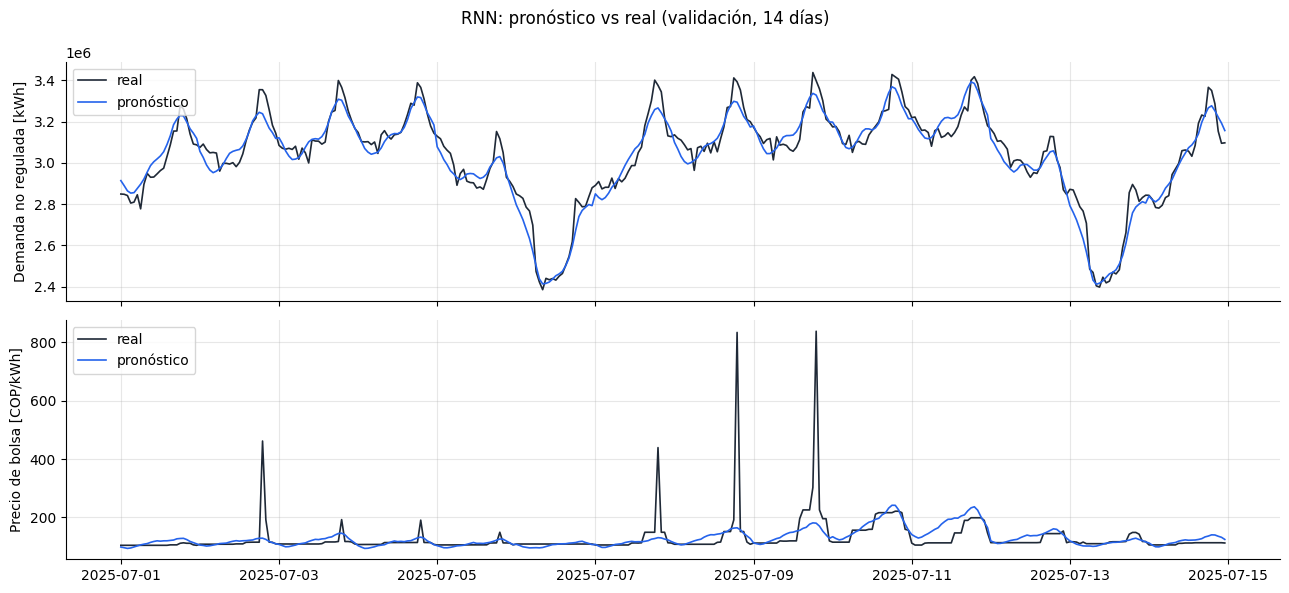

In [8]:
fig = pronostico_vs_real(datos, predicciones["val"], "val", dias=14, titulo="RNN: pronóstico vs real (validación, 14 días)")
guardar_figura(fig, "f2_01_rnn_pronostico_val")
plt.show()

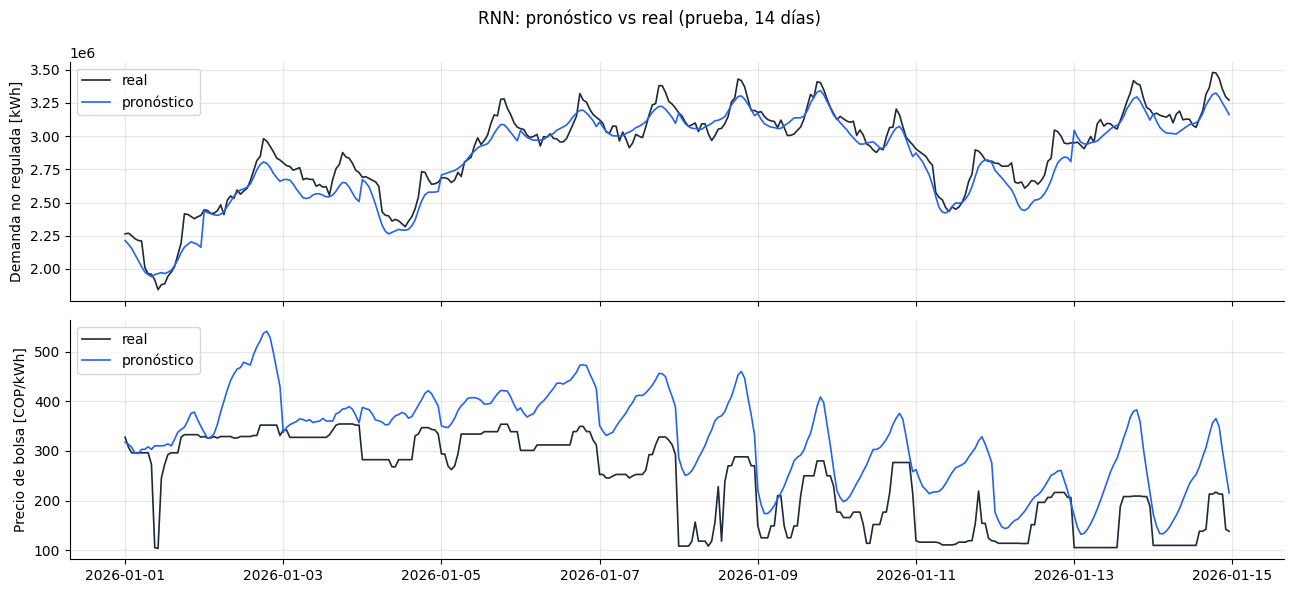

In [9]:
fig = pronostico_vs_real(datos, predicciones["test"], "test", dias=14, titulo="RNN: pronóstico vs real (prueba, 14 días)")
guardar_figura(fig, "f2_01_rnn_pronostico_test")
plt.show()

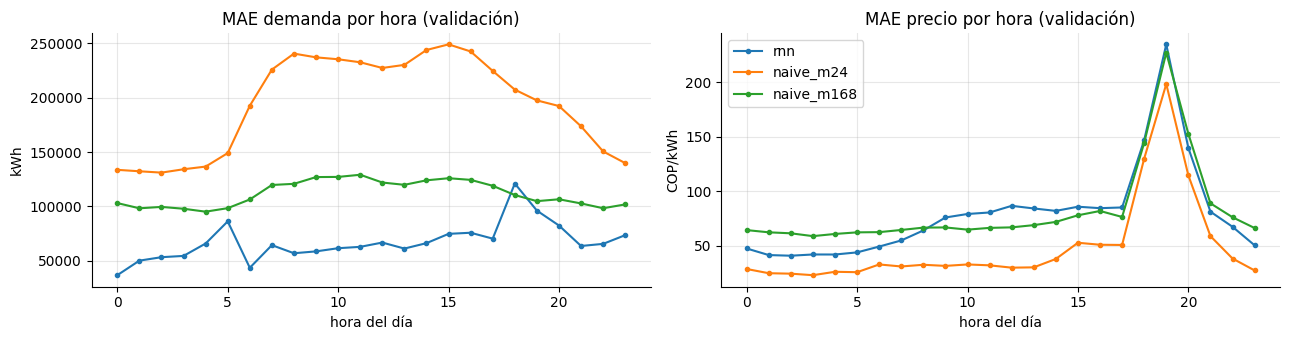

In [10]:
y_val = datos.y_original("val")
errores = {
    "rnn": error_por_hora(y_val, predicciones["val"]),
    "naive_m24": error_por_hora(y_val, naive_estacional(datos, "val", m=24)),
    "naive_m168": error_por_hora(y_val, naive_estacional(datos, "val", m=168)),
}
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
for nombre, e in errores.items():
    axes[0].plot(e.index - 1, e["demanda"], marker=".", label=nombre)
    axes[1].plot(e.index - 1, e["precio"], marker=".", label=nombre)
axes[0].set(title="MAE demanda por hora (validación)", xlabel="hora del día", ylabel="kWh")
axes[1].set(title="MAE precio por hora (validación)", xlabel="hora del día", ylabel="COP/kWh")
axes[1].legend()
fig.tight_layout()
guardar_figura(fig, "f2_01_rnn_error_por_hora")
plt.show()

In [11]:
hiperparametros = {**HP_MODELO, **HP_ENTRENAMIENTO, "parametros": contar_parametros(modelo),
                   "mejor_epoca": int(historial["val"].idxmin()), "epocas_entrenadas": len(historial)}
print(guardar_modelo(modelo, NOMBRE, hiperparametros))
print(guardar_resultados(NOMBRE, metricas, hiperparametros, historial))

C:\Users\57310\Desktop\pronostico-energia-nr\pronostico-energia-nr\results\modelos\rnn.pt
C:\Users\57310\Desktop\pronostico-energia-nr\pronostico-energia-nr\results\fase2\rnn
